# Hyperbolic Cavity with $d=25$ nm and $R=10$ nm

This notebook presents the few-mode fitting and subsequent master-equation analysis for a hyperbolic cavity with dimensions $d = 25 \text{ nm}$ and $R = 10 \text{ nm}$.

## Tools and utilities

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use("https://johannesfeist.eu/misc/jf_cb.mplstyle")
import pickle
import cmasher as cmr
import os

# Request 64-bit arithmetic from the optional fitting backend before it loads.
os.environ.setdefault('JAX_ENABLE_X64', 'True')

# load custom libraries
import sys
sys.path.append('..')
from methods.plotcolored import plotcolored
from methods.tools import debye_e_nm

## Full spectral density

We first import the full spectral density of the cavity across the second Reststrahlen band. This broader spectrum will later be used to identify the non-resonant contribution that is not captured by the few-mode fit.

In [2]:
# The text files contain a five-line metadata header.
file_path = '../data/DAchS-25-10_20_30-1_Fp_full.txt'
dataB = np.loadtxt(file_path, skiprows=5)

In [3]:
# load frequency in THz
freq_full = np.array(dataB[:,0])

# Convert frequency in THz to the photon energy hbar*omega in eV.
w_full = freq_full / 241.799

# load second column for R = 10 nm (skip others for this notebook)
Fp_full = np.array(dataB[:,1])

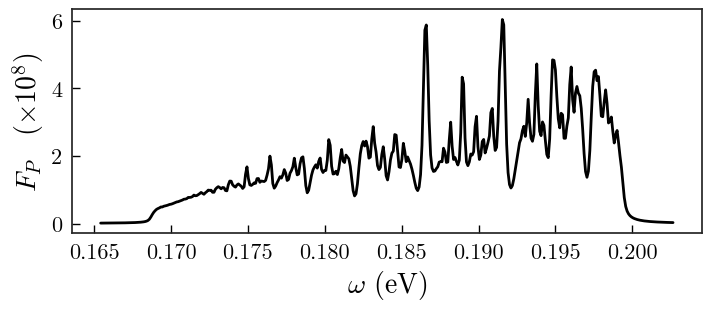

In [4]:
fig, ax = plt.subplots(figsize=(7,3))
ax.plot(w_full, Fp_full*1e-8)
ax.set_xlabel(r'$\omega \text{ (eV)}$', fontsize=20)
ax.set_ylabel(r'$F_P \quad (\times 10^8)$', fontsize=20);

In [5]:
# Compute the dipole-moment-normalized spectral density for later use.

k0_full = 2.0 * np.pi / (1240 / w_full)
eps0 = 55.264 * 1e-3  # e^2 eV^-1 nm^-1
# compute free-space dipole-moment-normalized spectral density J_0(w) / mu^2
J0 = k0_full**3 / (6.0 * np.pi**2 * eps0)
# compute the dipole-moment-normalized spectral density J(w) / mu^2 
Jdivmu2_full = Fp_full * J0

## Target spectral window

We begin with the Purcell-factor spectrum calculated in a narrow frequency window around the desired cavity resonance, corresponding to the mode discussed in Figure 5 of the paper. The first two data columns contain the frequency and the response for an emitter positioned 1 nm from the structure.

In [6]:
file_path = '../data/DAchS-25-10-1_Fp_near45THz.txt'
dataB = np.loadtxt(file_path, skiprows=5)

In [7]:
# store the frequency in THz
freq = np.array(dataB[:,0])
# consider the Purcell factor for the emitter at 1 nm
Fp = np.array(dataB[:,1])

The Purcell factor is converted into the physical spectral density $J(\omega)$ for a $\mu = 1 \text{ D}$ emitter. This requires converting frequency from THz to eV and multiplying the free-space spectral density by the calculated enhancement.

In [8]:
# define the dipole moment and the homogeneous linewidth of the emitter
mu_D = 1.0 
mu_e_nm = mu_D * debye_e_nm  # dipole moment in e nm
gamma_e_eV = 0.04*1e-3  # eV

# convert the frequency from THz to eV
w = freq / 241.799

k0 = 2.0 * np.pi / (1240 / w)
eps0 = 55.264 * 1e-3  # e^2 eV^-1 nm^-1

# compute dipole-moment-normalized free-space spectral density J(w) / mu^2
J0_divmu2 = k0**3 / (6.0 * np.pi**2 * eps0)
# compute free-space spectral density in eV^-1
J0 = k0**3 * mu_e_nm**2 / (6.0 * np.pi**2 * eps0)

# compute dipole-moment-normalized spectral density J(w) / mu^2
Jdivmu2 = Fp * J0_divmu2
# compute the spectral density J(w) in eV^-1
J = Fp * J0

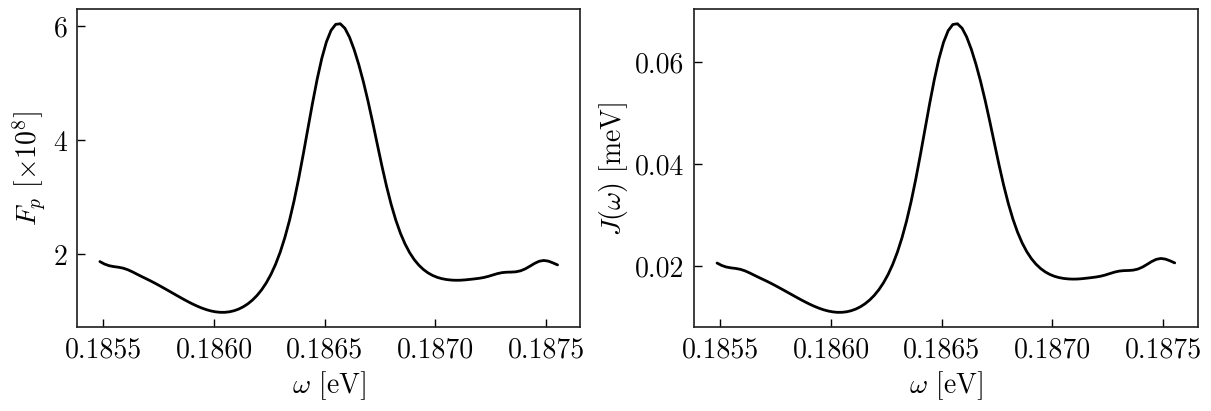

In [9]:
fig, ax = plt.subplots(figsize=(12,4), nrows=1, ncols=2)
ax[0].plot(w, Fp*1e-8, label='Fp')
ax[1].plot(w, J*1e3, label='J')

ax[0].tick_params(axis='both', labelsize=20)
ax[1].tick_params(axis='both', labelsize=20)

ax[0].set_xlabel(r'$\omega$ [eV]', fontsize=20)
ax[1].set_xlabel(r'$\omega$ [eV]', fontsize=20)
ax[0].set_ylabel(r'$F_p$ [$\times 10^8$]', fontsize=20)
ax[1].set_ylabel(r'$J(\omega)$ [meV]', fontsize=20);

### Electric Field Profile

We plot the corresponding electric field profile of this mode.

In [10]:
from scipy.interpolate import griddata
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle

In [11]:
file_path = '../data/DAchS-25-10-1_field_profile.txt'
dataB = np.loadtxt(file_path, skiprows=8)

x, y, z = dataB[:,0], dataB[:,1], dataB[:,2]

In [12]:
xs = np.linspace(0.0, 20e-9, 200)
ys = np.linspace(-30E-9, 10E-9, 200)
X, Y = np.meshgrid(xs, ys)
Z = griddata((x, y), z, (X, Y), method='linear')  # or 'linear'
Z = np.where(Z < 0, 1, Z)

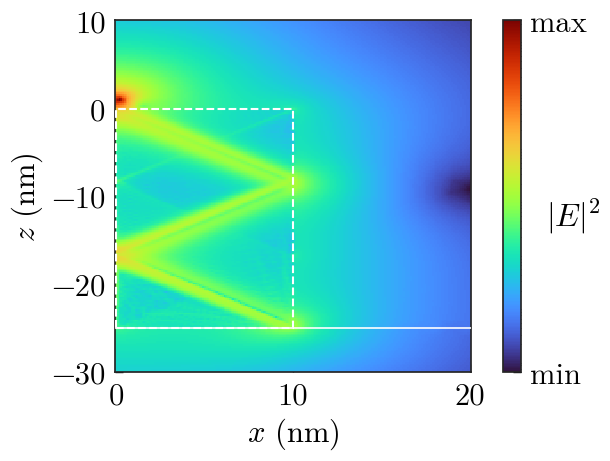

In [13]:
fig, ax = plt.subplots(figsize=(6,4.5))
pcm = ax.pcolormesh(X*1e9, Y*1e9, Z, norm=LogNorm(), rasterized=True)
cbar = fig.colorbar(pcm, ax=ax, shrink=1.0)
cbar.ax.set_ylabel(r'$|E|^2$', rotation=0, fontsize=23, labelpad=-10)
cbar.set_ticks([Z.min(), Z.max()])
cbar.set_ticklabels(['min', 'max'], fontsize=22) 

ax.set_xlabel(r'$x \text{ (nm)}$', fontsize=22)
ax.set_ylabel(r'$z \text{ (nm)}$', fontsize=22)
ax.tick_params(axis='both', labelsize=22)

ax.axhline(y=-25, color='white', lw=1.2, zorder=3)

cavity = Rectangle((0, -25), 10, 25,
                   linewidth=1.5,
                   edgecolor='white',
                   facecolor='none',
                   linestyle='--',
                   zorder=3)
ax.add_patch(cavity);

## Few-Mode Fitting

We now fit the calculated spectral density with the few-mode model
$$
    J_\text{fm}(\omega)= \frac{\mu^2}{\pi} \mathrm{Im} \Bigg\{ \vec{g}^{T} \frac{1}{\mathbf{\tilde{H}}-\omega} \vec{g} \Bigg\}.
$$
The non-Hermitian matrix $\tilde{\mathbf{H}}=\omega_{ij}-i\kappa_i\delta_{ij}/2$ contains the coherent mode couplings and Markovian losses. This step follows the treatment of Medina *et al.* (Phys. Rev. Lett. **126**, 093601, 2021).

In [14]:
# import custom module for applying few-mode fitting
from methods.apply_few_mode import FewModeFit

We initialize a six-mode model using approximate resonance energies, linewidths, and emitter-mode couplings. These values serve only as starting points for the numerical optimization. We fit the dipole-moment-normalized spectral density so that the resulting environmental parameters can subsequently be used for different emitter dipole moments.

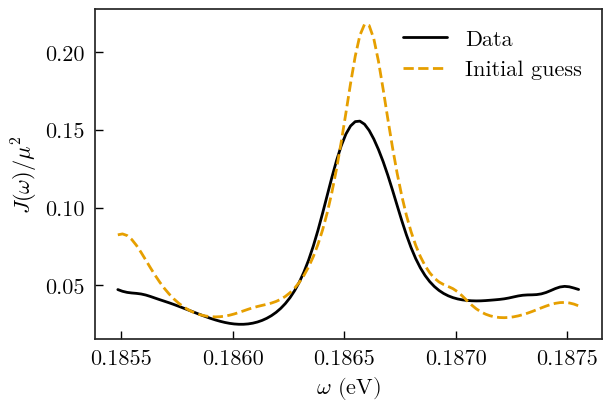

In [15]:
# Initial mode energies and coherent couplings (eV).
H = np.diag([0.1855, 0.1860, 0.1861, 0.1866, 0.1870, 0.1875])
Nm = H.shape[0]
# Initial mode linewidths (eV).
K = np.r_[4e-4, 5e-4, 3e-4, 3e-4, 2e-4, 5e-4]
# Initial dipole-normalized emitter-mode couplings.
g = np.r_[[7E-3, 1e-3, 2E-3, 10E-3, 2E-3, 5E-3]].reshape(1, Nm)

fmc = FewModeFit(w, Jdivmu2, H, K, g)
fmc.initialize();

We now optimize the model parameters to reproduce the calculated spectral density.

Fit error: 0.00388525


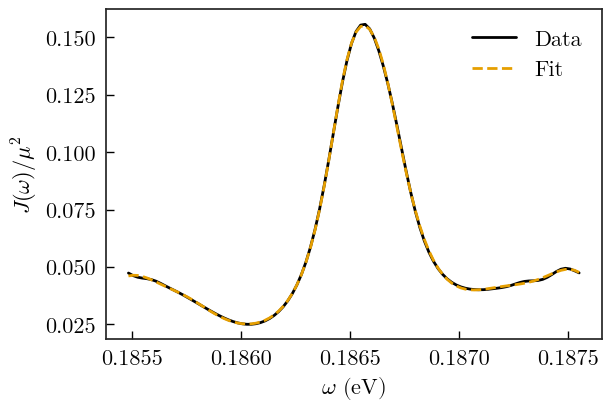

In [16]:
fmc.fit();

After fitting, we diagonalize the lossy mode Hamiltonian $\tilde{\mathbf{H}}$. Its complex eigenfrequencies determine the resonance positions and quality factors, while the transformed couplings determine the normalized effective mode volumes.

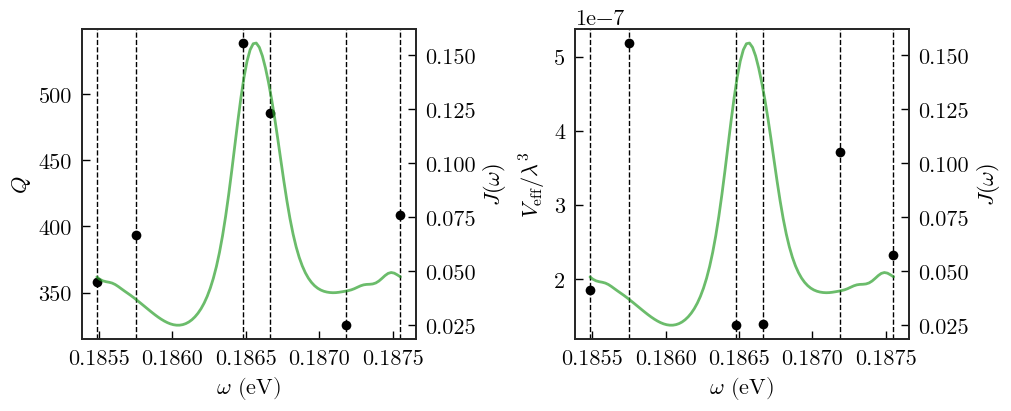

In [17]:
Omega, Q, Veff_norm = fmc.compute_figures_of_merit()

We next interpolate the fitted spectral density across the second Reststrahlen band. This allows the resonant few-mode contribution to be separated from the residual contribution treated perturbatively below.

In [18]:
Jfit_interp_func = fmc.create_interpolator(w_min=0.165, w_max=0.203)
w_interp = np.linspace(0.165, 0.203, 400)
Jfit_interp = Jfit_interp_func(w_interp)

The following diagnostic overlays the original and fitted spectral densities and shows the mode-resolved quality factors and normalized effective mode volumes. The vertical guides mark the real parts of the fitted complex resonance energies.

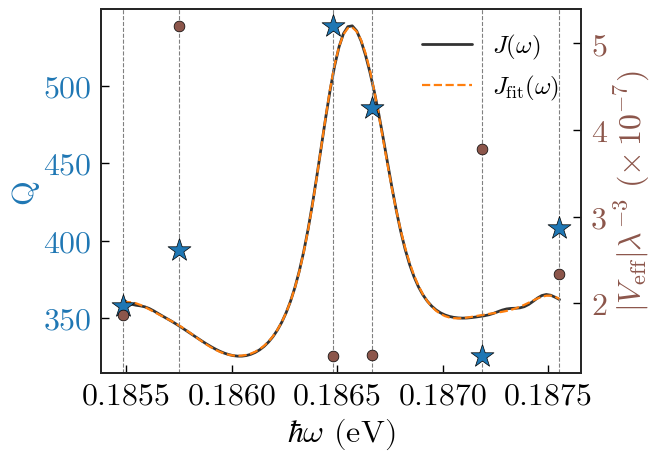

In [19]:
fig, ax1 = plt.subplots()

Jfit_interp_full = Jfit_interp_func(w) * mu_e_nm**2 

# Colors
c_Q     = '#1f77b4'   # blue, for Q (left axis)
c_V     = '#8c564b'   # brown, for V_eff (right axis)
c_true  = '#333333'   # near-black, true J
c_fit   = '#ff7f0e'   # orange, few-mode fit

# Spectral density curves (use a hidden 3rd axis so they don't conflict with left scale)
ax_J = ax1.twinx()
ax_J.plot(w, J, color=c_true, lw=2, label=r'$J(\omega)$')
ax_J.plot(w, Jfit_interp_full,  color=c_fit, lw=1.6, ls='--', label=r'$J_{\text{fit}}(\omega)$')
ax_J.set_yticks([])              # hide ticks
ax_J.spines['right'].set_visible(False)
ax_J.set_zorder(1)               # behind markers

# Vertical guides at mode frequencies (optional, very faint)
for wi in np.real(Omega):
    ax1.axvline(wi, color='gray', lw=0.8, ls='--', alpha=1.0, zorder=0)

# Q on left axis
ax1.scatter(np.real(Omega), Q, marker='*', s=300,
            color=c_Q, edgecolor='black', lw=0.5,
            label='Q', zorder=3)
ax1.set_xlabel(r'$\hbar \omega$ (eV)', fontsize=23)
ax1.set_ylabel('Q', color=c_Q, fontsize=23)
ax1.tick_params(axis='x', labelsize=23)
ax1.tick_params(axis='y', labelcolor=c_Q, labelsize=23)
ax1.set_zorder(2)
ax1.patch.set_visible(False)     

# V_eff on right axis
ax2 = ax1.twinx()
ax2.scatter(np.real(Omega), np.abs(Veff_norm)*1e7, marker='o', s=60,
            color=c_V, edgecolor='black', lw=0.5,
            label=r'$|V_\mathrm{eff}| \lambda^{-3}$', zorder=3)
ax2.set_ylabel(r'$|V_\mathrm{eff}| \lambda^{-3} \,\, (\times \, 10^{-7})$', 
               color=c_V, fontsize=23)
ax2.tick_params(axis='y', labelcolor=c_V, labelsize=23)
ax2.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

# Combined legend
handles = ax_J.get_lines() #+
           #[ax1.collections[0], ax2.collections[0]])
labels  = [h.get_label() for h in handles]
ax1.legend(handles, labels, frameon=False, fontsize=18);

In [20]:
# Complex light-matter couplings normalized by the dipole moment; these are
# equivalently proportional to the single-polariton electric fields.
g_tilde = fmc.g_tilde

# Recover the fitted coupled-mode parameters as NumPy arrays.
H, kappas, gs = fmc.fitted_parameters()

We collect the fitted spectrum, coupled-mode parameters, and diagonalized-mode figures of merit in a single dictionary and serialize it for the light–matter analysis and future reuse.

In [21]:
data = {
    'fit': {
        'w': w, 
        'J': J, 
        'w_interp': w_interp, 
        'Jfit_interp': Jfit_interp
    },    
    'coupled_modes': {
        'H': H, 
        'kappas': kappas, 
        'g': gs
    },
    'uncoupled_modes': {
        'Omega': Omega,
        'Q': Q,
        'Veff_norm': Veff_norm,
        'gs': g_tilde
    }
}

with open('few_mode_fits/DAchS-25-10-1_6modes_fit.pickle', 'wb') as handle:
    pickle.dump(data, handle, protocol=pickle.HIGHEST_PROTOCOL)

## Load saved few-mode fitting results (optional)

Run this section only when loading a previously saved fit—for example, to skip the optimization and proceed directly to the light–matter analysis. When running the notebook from the beginning, these cells simply reload the results saved above.

In [19]:
# load data
filename = 'few_mode_fits/DAchS-25-10-1_6modes_fit.pickle'
with open(filename, 'rb') as handle:
    data = pickle.load(handle)

In [20]:
w, J = data['fit']['w'], data['fit']['J']
w_interp, Jfit_interp = data['fit']['w_interp'], data['fit']['Jfit_interp']
H = data['coupled_modes']['H']
kappas = data['coupled_modes']['kappas']
gs = data['coupled_modes']['g']
Nm = kappas.shape[0]

## Separate Perturbative Part

The few-mode fit describes the resonant part of the electromagnetic environment. We interpolate the fit over the full frequency grid and subtract it from the complete spectral density. The residual contribution is then treated perturbatively.

**Note:** Unless stated otherwise, the following analysis uses $\mu = 1 \text{ D}$.

In [22]:
from scipy.interpolate import CubicSpline
from methods.perturbative import lamb_shift_fm, decay_rate_fm

In [23]:
# Reconstruct the saved, dipole-normalized fit on the full frequency grid.
spline = CubicSpline(w_interp, Jfit_interp, bc_type='not-a-knot', extrapolate=False)

def Jfit_func(w):
    res = spline(w)
    return np.where(np.isnan(res), 0.0, res)

# Restore the physical spectral densities for the selected dipole moment.
J_full = Jdivmu2_full * mu_e_nm**2 
Jfit = Jfit_func(w_full) * mu_e_nm**2
diff = J_full - Jfit 

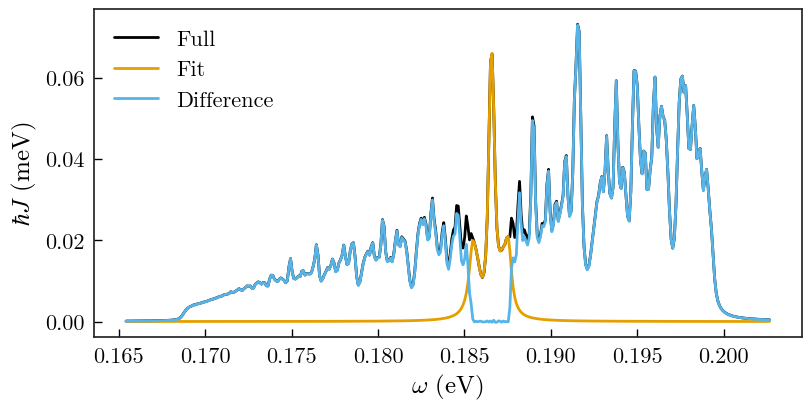

In [24]:
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(w_full, J_full*1e3, label='Full')
ax.plot(w_full, Jfit*1e3, label='Fit')
ax.plot(w_full, diff*1e3, label='Difference')
ax.set_xlabel(r'$\omega \text{ (eV)}$', fontsize=18)
ax.set_ylabel(r'$\hbar J \text{ (meV)} $', fontsize=18)
ax.legend();

The residual spectral density produces a perturbative Lamb shift. We evaluate this correction across the fitted frequency window and use it to map the bare emitter energy $\omega_e$ to the shifted energy $\tilde{\omega}_e$.

In [25]:
we_ls = np.linspace(w[0], w[-1], 50)

diffs = []
for wi in we_ls:
    val = lamb_shift_fm(wi, w_full, diff)
    diffs.append(val)

ldif = np.array(diffs)
we_new = we_ls - ldif

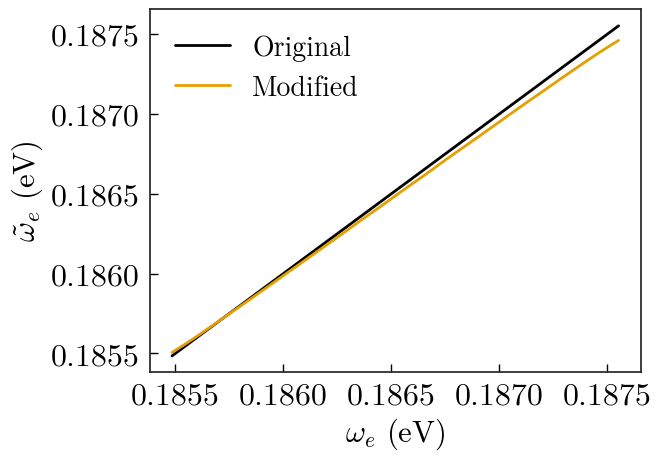

In [26]:
fig, ax = plt.subplots()
ax.plot(we_ls, we_ls, label='Original')
ax.plot(we_ls, we_new, label='Modified')
ax.set_xlabel(r'$\omega_e \text{ (eV)}$', fontsize=22)
ax.set_ylabel(r'$\tilde{\omega}_e \text{ (eV)}$', fontsize=22)
ax.tick_params(axis='both', labelsize=23)
ax.legend(prop={'size': 20});

The residual spectral density produces a perturbative contribution to the emitter decay rate. Within the Markov approximation, this frequency-dependent contribution is

$$\gamma_{\mathrm{pert}}(\omega_e)=2\pi\,\Delta J(\omega_e).$$

We evaluate this contribution at every emitter energy used in the dispersion calculation.

In [27]:
gamma_e_new = decay_rate_fm(we_ls, w_full, diff)

## Spectrum of the Effective Hamiltonian

We now compute the spectrum of the effective non-Hermitian Hamiltonian
\begin{equation}
    \hat{\mathcal{H}}_\text{eff} = \hat{H}'_\text{S} - \frac{i}{2} \sum_i \kappa_i \hat{a}^{\dagger}_i \hat{a}_i - \frac{i}{2}(\gamma_e + \gamma_{\mathrm{pert}})\hat b^\dagger\hat b.
\end{equation}
Here, $\hat{H}'_\mathrm{S}$ contains the shifted emitter energy and the fitted few-mode Hamiltonian.

In [28]:
from methods.mastereq import MasterEquationQtp

The effective quantum model is constructed from the fitted coupled-mode Hamiltonian, mode decay rates, and emitter-mode couplings. Restricting the Hilbert space to a single excitation is sufficient for the linear-response dynamics considered here.

In [29]:
meq = MasterEquationQtp(Nm=Nm, Ne=1, Nexc=1)
meq.provide_fm_pars(H, gs, kappas);

We sweep the emitter transition across the fitted spectral window and diagonalize the non-Hermitian effective Hamiltonian at each point. This reveals the hybridized branches and associated avoided crossings.

In [30]:
vals, vecs = meq.get_Heff_dispersion(
    we_new, mu=mu_e_nm, gamma_e=gamma_e_new+gamma_e_eV
)

The dispersion branches are coloured according to their emitter component $|c_e|^2$. This distinguishes predominantly photonic modes from branches with appreciable emitter character.

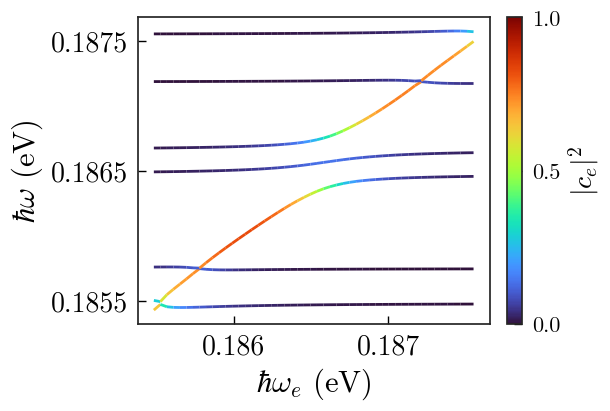

In [31]:
# plotcolored wants a plot axis as input, generate an empty figure and axis
fig, ax = plt.subplots(figsize=(6,4))
# make sure all lines are colored with the same mapping to the data range, from 0 to 1
norm = plt.matplotlib.colors.Normalize(0,1)
for ii in range(1, vals.shape[1]):
    # Colour each branch by the emitter population in the corresponding eigenvector.
    im = plotcolored(ax, we_ls, vals[:,ii].real, abs(vecs[:,1,ii])**2, norm=norm)
# plotcolored does not automatically rescale the axis to the data limits, do it now
ax.autoscale()
ax.set_xlabel(r"$\hbar \omega_e \text{ (eV)}$", fontsize=22)
ax.set_ylabel(r"$\hbar \omega \text{ (eV)}$", fontsize=22)
cb = plt.colorbar(im, ax=ax)
cb.set_label("$|c_e|^2$", fontsize=20)
ax.tick_params(axis='both', labelsize=20)
ax.set_yticks([0.1855,0.1865,0.1875])

cb.set_ticks([0,0.5,1])

In [32]:
# Locate the emitter energy at which the selected branches have their minimum splitting.
spl = vals[:,5].real - vals[:,3].real
we_indx = np.where(spl == np.min(spl))
spl[we_indx], we_ls[we_indx]

(array([0.00038898]), array([0.18662406]))

In [33]:
# compute the perturbative decay rate at resonance 
gamma_e_new_at_res = gamma_e_new[we_indx]

## Time Dynamics

Finally, we propagate the dynamics of an initially excited emitter coupled to the fitted modes. Repeating the calculation for several dipole moments shows how the light–matter coupling strength affects population exchange and decay. Each subsection rebuilds the model, sets the emitter parameters, solves the master equation, and plots the emitter and mode populations.

In [34]:
meq = MasterEquationQtp(Nm=Nm, Ne=1, Nexc=1)

In [35]:
# Tune the emitter to the energy selected from the avoided-crossing analysis.
meq.provide_fm_pars(H, gs, kappas)
meq.set_qe_pars(omega_e=we_new[we_indx][0], mu=mu_e_nm, gamma_e=gamma_e_new_at_res+gamma_e_eV)
meq.setup_ops()
meq.initial_state()

Quantum object: dims=[[2, 2, 2, 2, 2, 2, 2], [1]], shape=(8, 1), type='ket', dtype=Dense
Qobj data =
[[0.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]]

In [36]:
tsfs, sol = meq.solve(t_max=4e4, n_t=1000)

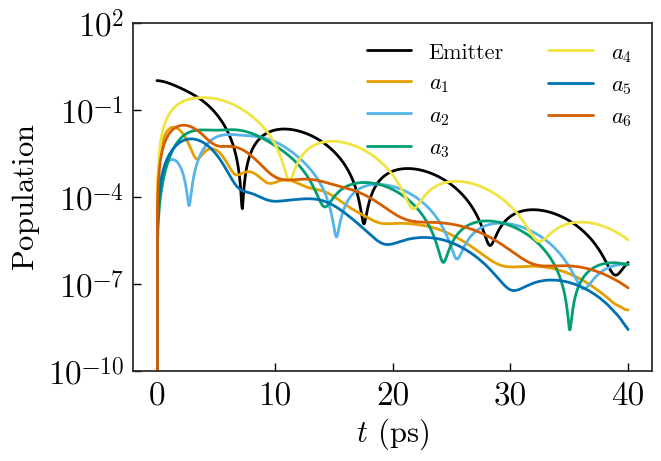

In [38]:
fig, ax = plt.subplots()
ax.plot(tsfs*1e-3, sol.expect[-1], label="Emitter")
for ii in range(Nm):
    ax.plot(tsfs*1e-3, sol.expect[ii], label=r"$a_{%i}$" % (ii+1))
ax.set_xlabel(r"$t \text{ (ps)}$", fontsize=22)
ax.set_ylabel(r"$\text{Population}$", fontsize=22)
ax.tick_params(axis='both', labelsize=24)
ax.legend(ncol=2);
ax.set_yscale('log')
ax.set_ylim(1e-10, 100)

## Dynamics for $\mu = 0.75 \text{ D}$

In [38]:
mu_D = 0.75
mu_e_nm = mu_D * debye_e_nm

In [39]:
# construct the physical spectral density (and the difference) with the current dipole moment
J_full = Jdivmu2_full * mu_e_nm**2 
Jfit = Jfit_func(w_full) * mu_e_nm**2
diff = J_full - Jfit 

In [40]:
we_ls = np.linspace(w[0], w[-1], 50)

diffs = []
for wi in we_ls:
    val = lamb_shift_fm(wi, w_full, diff)
    diffs.append(val)

ldif = np.array(diffs)
we_new = we_ls - ldif

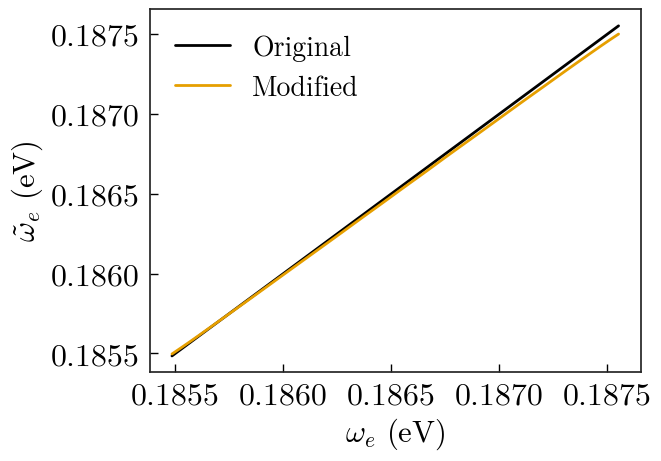

In [41]:
fig, ax = plt.subplots()
ax.plot(we_ls, we_ls, label='Original')
ax.plot(we_ls, we_new, label='Modified')
ax.set_xlabel(r'$\omega_e \text{ (eV)}$', fontsize=22)
ax.set_ylabel(r'$\tilde{\omega}_e \text{ (eV)}$', fontsize=22)
ax.tick_params(axis='both', labelsize=23)
ax.legend(prop={'size': 20});

In [42]:
# compute the perturbative decay rate
gamma_e_new = decay_rate_fm(we_ls, w_full, diff)

In [43]:
meq = MasterEquationQtp(Nm=Nm, Ne=1, Nexc=1)
meq.provide_fm_pars(H, gs, kappas);
vals, vecs = meq.get_Heff_dispersion(we_new, mu=mu_e_nm, gamma_e=gamma_e_new+gamma_e_eV)

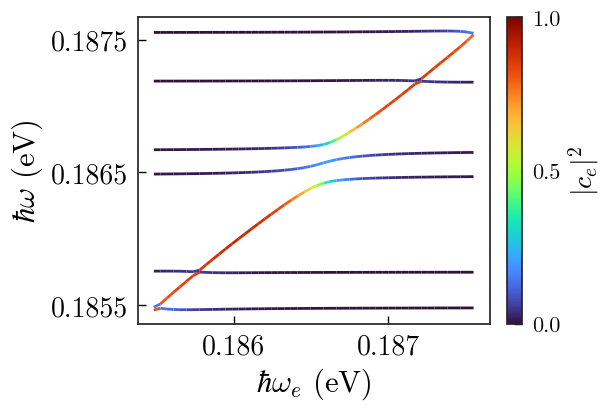

In [44]:
# plotcolored wants a plot axis as input, generate an empty figure and axis
fig, ax = plt.subplots(figsize=(6,4))
# make sure all lines are colored with the same mapping to the data range, from 0 to 1
norm = plt.matplotlib.colors.Normalize(0,1)
for ii in range(1, vals.shape[1]):
    # Colour each branch by the emitter population in the corresponding eigenvector.
    im = plotcolored(ax, we_ls, vals[:,ii].real, abs(vecs[:,1,ii])**2, norm=norm)
# plotcolored does not automatically rescale the axis to the data limits, do it now
ax.autoscale()
ax.set_xlabel(r"$\hbar \omega_e \text{ (eV)}$", fontsize=22)
ax.set_ylabel(r"$\hbar \omega \text{ (eV)}$", fontsize=22)
cb = plt.colorbar(im, ax=ax)
cb.set_label("$|c_e|^2$", fontsize=20)
ax.tick_params(axis='both', labelsize=20)
ax.set_yticks([0.1855,0.1865,0.1875])

cb.set_ticks([0,0.5,1])

In [45]:
# Locate the emitter energy at which the selected branches have their minimum splitting.
spl = vals[:,5].real - vals[:,3].real
we_indx = np.where(spl == np.min(spl))
spl[we_indx], we_ls[we_indx]

(array([0.00029046]), array([0.18658186]))

In [46]:
meq = MasterEquationQtp(Nm=Nm, Ne=1, Nexc=1)

In [47]:
meq.provide_fm_pars(H, gs, kappas)
meq.set_qe_pars(omega_e=we_new[we_indx][0], mu=mu_e_nm, gamma_e=gamma_e_new[we_indx]+gamma_e_eV)
meq.setup_ops()
meq.initial_state()

Quantum object: dims=[[2, 2, 2, 2, 2, 2, 2], [1]], shape=(8, 1), type='ket', dtype=Dense
Qobj data =
[[0.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]]

In [48]:
tsfs, sol = meq.solve(t_max=4e4, n_t=10000)

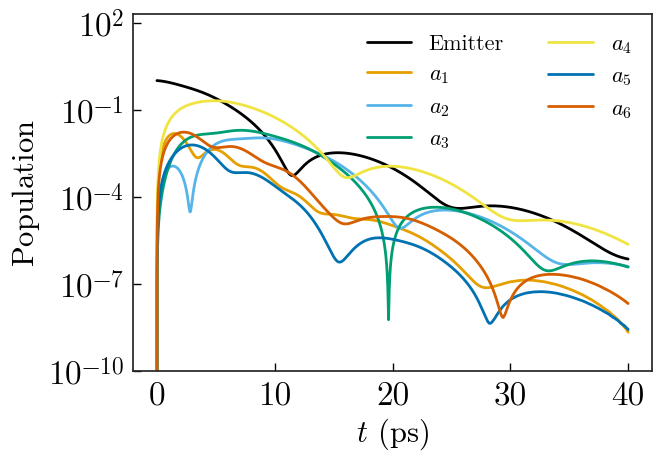

In [49]:
fig, ax = plt.subplots()
ax.plot(tsfs*1e-3, sol.expect[-1], label="Emitter")
for ii in range(Nm):
    ax.plot(tsfs*1e-3, sol.expect[ii], label=r"$a_{%i}$" % (ii+1))
ax.set_xlabel(r"$t \text{ (ps)}$", fontsize=22)
ax.set_ylabel(r"$\text{Population}$", fontsize=22)
ax.tick_params(axis='both', labelsize=24)
ax.legend(ncol=2);
ax.set_yscale('log')
ax.set_ylim(1e-10, 200);

## Dynamics for $\mu = 0.5 \text{ D}$

In [50]:
mu_D = 0.5
mu_e_nm = mu_D * debye_e_nm

In [51]:
# construct the physical spectral density (and the difference) with the current dipole moment
J_full = Jdivmu2_full * mu_e_nm**2 
Jfit = Jfit_func(w_full) * mu_e_nm**2
diff = J_full - Jfit 

In [52]:
we_ls = np.linspace(w[0], w[-1], 50)

diffs = []
for wi in we_ls:
    val = lamb_shift_fm(wi, w_full, diff)
    diffs.append(val)

ldif = np.array(diffs)
we_new = we_ls - ldif

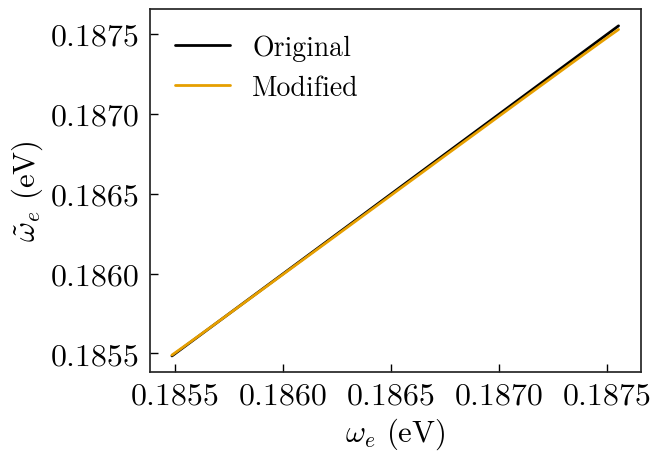

In [53]:
fig, ax = plt.subplots()
ax.plot(we_ls, we_ls, label='Original')
ax.plot(we_ls, we_new, label='Modified')
ax.set_xlabel(r'$\omega_e \text{ (eV)}$', fontsize=22)
ax.set_ylabel(r'$\tilde{\omega}_e \text{ (eV)}$', fontsize=22)
ax.tick_params(axis='both', labelsize=23)
ax.legend(prop={'size': 20});

In [54]:
# compute the perturbative decay rate
gamma_e_new = decay_rate_fm(we_ls, w_full, diff)

In [55]:
meq = MasterEquationQtp(Nm=Nm, Ne=1, Nexc=1)
meq.provide_fm_pars(H, gs, kappas);
vals, vecs = meq.get_Heff_dispersion(we_new, mu=mu_e_nm, gamma_e=gamma_e_new+gamma_e_eV)

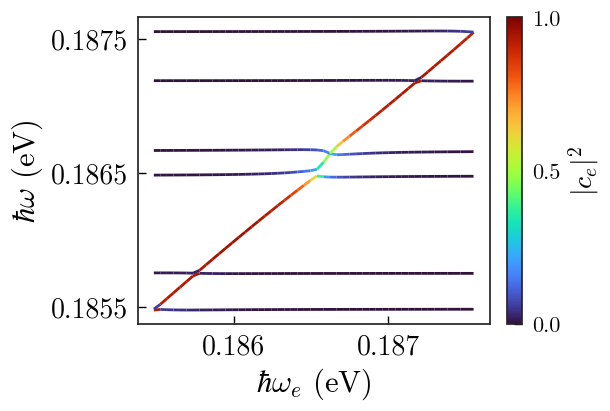

In [56]:
# plotcolored wants a plot axis as input, generate an empty figure and axis
fig, ax = plt.subplots(figsize=(6,4))
# make sure all lines are colored with the same mapping to the data range, from 0 to 1
norm = plt.matplotlib.colors.Normalize(0,1)
for ii in range(1, vals.shape[1]):
    # Colour each branch by the emitter population in the corresponding eigenvector.
    im = plotcolored(ax, we_ls, vals[:,ii].real, abs(vecs[:,1,ii])**2, norm=norm)
# plotcolored does not automatically rescale the axis to the data limits, do it now
ax.autoscale()
ax.set_xlabel(r"$\hbar \omega_e \text{ (eV)}$", fontsize=22)
ax.set_ylabel(r"$\hbar \omega \text{ (eV)}$", fontsize=22)
cb = plt.colorbar(im, ax=ax)
cb.set_label("$|c_e|^2$", fontsize=20)
ax.tick_params(axis='both', labelsize=20)
ax.set_yticks([0.1855,0.1865,0.1875])

cb.set_ticks([0,0.5,1])

In [57]:
# Locate the emitter energy at which the selected branches have their minimum splitting.
spl = vals[:,4].real - vals[:,3].real
we_indx = np.where(spl == np.min(spl))
spl[we_indx], we_ls[we_indx]

(array([4.9567334e-05]), array([0.18653966]))

In [58]:
meq = MasterEquationQtp(Nm=Nm, Ne=1, Nexc=1)

In [59]:
# Tune the emitter to the energy selected from the avoided-crossing analysis.
meq.provide_fm_pars(H, gs, kappas)
meq.set_qe_pars(omega_e=we_new[we_indx][0], mu=mu_e_nm, gamma_e=gamma_e_new[we_indx]+gamma_e_eV)
meq.setup_ops()
meq.initial_state()

Quantum object: dims=[[2, 2, 2, 2, 2, 2, 2], [1]], shape=(8, 1), type='ket', dtype=Dense
Qobj data =
[[0.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]]

In [60]:
tsfs, sol = meq.solve(t_max=4e4, n_t=10000)

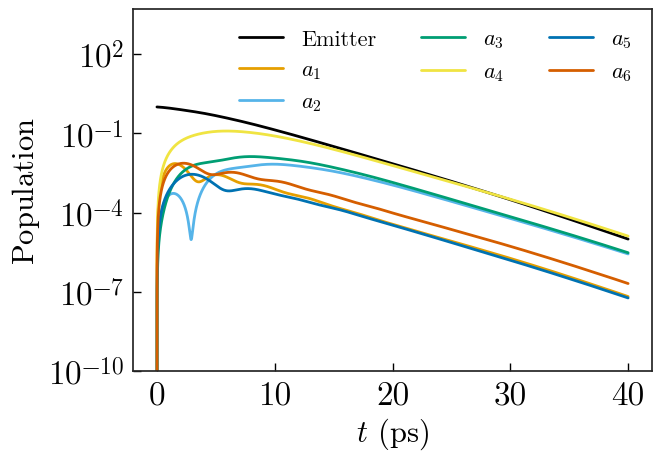

In [61]:
fig, ax = plt.subplots()
ax.plot(tsfs*1e-3, sol.expect[-1], label="Emitter")
for ii in range(Nm):
    ax.plot(tsfs*1e-3, sol.expect[ii], label=r"$a_{%i}$" % (ii+1))
ax.set_xlabel(r"$t \text{ (ps)}$", fontsize=22)
ax.set_ylabel(r"$\text{Population}$", fontsize=22)
ax.tick_params(axis='both', labelsize=24)
ax.legend(ncol=3);
ax.set_yscale('log')
ax.set_ylim(1e-10, 5000);